

## Submission Summary

| **Field**                         | **Value**                                                                                                                                     |
| --------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------- |
| **Group number**                  | 24                                                                                                                                            |
| **Your full name**                | Solomon Buba Tarfa                                                                                                                            |
| **Dataset**                       | Bank Marketing                                                                                                                                |
| **Depth track**                   | Classification Depth                                                                                                                          |
| **Team members**                  | Isimbabi Hafsat,
⁠Ifeoluwanimi P. Shobayo, Adu Inioluwa, Sanusi Barakat,Eme Gift Onyiyechi,Oluwatosin Olotu,Tamuno Charity John,⁠Ganiyat Oresanwo,⁠Nwadike Chidinma Favour, Aniemeka Chidimma, Justin Obaji Ebuka, Glory Easy Ndekwu|
| **Final model**                   | Random Forest, threshold tuned to 0.40                                                                                                        |
| **Stratified Dummy F1 / ROC AUC** | 0.486 / 0.509                                                                                                                                 |
| **Final model F1 / ROC AUC**      | 0.701 / 0.774                                                                                                                                 |
| **Leakage columns dropped**       | `duration` — used only for EDA/SQL storytelling in Part 1; excluded from all modeling features because it is only known after a call happens. |
| **Full run time on Colab**        | 6 minutes                                                                                                                          |



In [1]:
# kagglehub lets us pull the dataset straight from Kaggle inside the notebook,
# so it reproduces on any fresh Colab session without manual uploads
!pip install -q kagglehub imbalanced-learn

import kagglehub                                  # downloads the Kaggle dataset
import os                                         # to build file paths
import sqlite3                                    # lightweight SQL database, built into Python
import numpy as np                                # numeric arrays
import pandas as pd                               # dataframes (our main data structure)
import matplotlib.pyplot as plt                   # plotting
import seaborn as sns                             # nicer statistical plots, built on matplotlib

# Used to split our data into training and testing sets
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Used to standardize numerical features
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Used for K-Means clustering
from sklearn.cluster import KMeans

# Used to reduce many features into 2 dimensions for visualization
from sklearn.decomposition import PCA

# Evaluation metrics for our classification models
from sklearn.metrics import (
      accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
      ConfusionMatrixDisplay, precision_recall_curve, RocCurveDisplay
)
# A simple baseline model
# Our real models must perform better than this
from sklearn.dummy import DummyClassifier

# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from imblearn.over_sampling import SMOTE            #for imbalance handling in part 5 

#Fixed seed everywhere so results are reproducible run to run
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

#make plots a decent default size
plt.rcParams['figure.figsize'] = (8, 5)
sns.set_style("whitegrid")

# Part 1. Data Foundation


Business framing: a bank ran a telemarketing campaign to sell term deposits. deposit (yes/no) tells us whether the customer subscribed. We want to find natural customer segments (clustering) and predict who will subscribe (classification), so the bank can call the right people.

In [2]:
# Download the Kaggle dataset into the Colab environment.
# This dataset ("janiobachmann/bank-marketing-dataset") ships one file: bank.csv
path = kagglehub.dataset_download("janiobachmann/bank-marketing-dataset")
print("Path to dataset files:", path)

file_path = os.path.join(path, "bank.csv")
df = pd.read_csv(file_path)          

print("Rows, columns:", df.shape)
df.head()

Path to dataset files: C:\Users\Tarfa_Jr\.cache\kagglehub\datasets\janiobachmann\bank-marketing-dataset\versions\1
Rows, columns: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [3]:
# Push the raw data into a SQLite database so we can run real SQL queries on it.
# SQLite needs no server — it's just a local file, which is why it's ideal for a notebook.
conn = sqlite3.connect("bank_marketing.db")      #create or open a local db filer
df.to_sql("customers", conn, if_exists="replace", index=False)  #writing dataframe as sql table
print("Table 'customers' created with", pd.read_sql("SELECT COUNT(*) AS n FROM customers",conn)['n'][0], "rows")

Table 'customers' created with 11162 rows


### SQL Query 1:  Subscription Rate by Job

In [4]:
query1 = '''
SELECT job,
       COUNT(*) AS n_customers,
       SUM(CASE WHEN deposit = 'yes' THEN 1 ELSE 0 END) AS n_subscribed,
       ROUND(100.0 * SUM(CASE WHEN deposit = 'yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_subscribed
FROM customers
GROUP BY job
ORDER BY pct_subscribed DESC
'''
job_rates = pd.read_sql(query1, conn)
job_rates


,job,n_customers,n_subscribed,pct_subscribed
0,student,360,269,74.7
1,retired,778,516,66.3
2,unemployed,357,202,56.6
3,management,2566,1301,50.7
4,unknown,70,34,48.6
5,admin.,1334,631,47.3
6,self-employed,405,187,46.2
7,technician,1823,840,46.1
8,services,923,369,40.0
9,housemaid,274,109,39.8


What we learned: Subscription rate varies a lot by job. student (74.7%) and retired (66.3%) customers subscribe at far higher rates than the overall average, while blue-collar (36.4%) and entrepreneur (37.5%) subscribe least. This makes intuitive sense  students and retirees likely have more flexible time to engage with a call and different savings priorities than working professionals.

### SQL Query 2: Subscription Rate by Previous Outcome

In [5]:
query2 = '''
SELECT poutcome,
       COUNT(*) AS n_customers,
       ROUND(100.0 * SUM(CASE WHEN deposit = "yes" THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_subscribed,
       ROUND(AVG(previous),2) AS avg_previous_contacts
       FROM customers
       GROUP BY poutcome
       ORDER BY pct_subscribed DESC
       
'''
poutcome_rates = pd.read_sql(query2, conn)
poutcome_rates

,poutcome,n_customers,pct_subscribed,avg_previous_contacts
0,success,1071,91.3,3.12
1,other,537,57.2,4.16
2,failure,1228,50.3,3.02
3,unknown,8326,40.7,0.00


What we learned: Customers whose previous campaign outcome (poutcome) was "success" subscribe again 91.3% of the time, versus only 40.7% for customers with no prior contact history (unknown) and 50.3% for a prior "failure". Past behavior is clearly one of the strongest signals in this dataset  a customer who said yes before is overwhelmingly likely to say yes again.

### SQL Query 3:  Average Balance by Job

In [6]:
query3 = '''
SELECT
    CASE
        WHEN duration < 120 THEN '0-2 min'
        WHEN duration < 300 THEN '2-5 min'
        WHEN duration < 600 THEN '5-10 min'
        ELSE '10+ min'
    END AS call_length_bucket,
    COUNT(*) AS n_calls,
    ROUND(100.0 * SUM(CASE WHEN deposit = 'yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_subscribed
FROM customers
GROUP BY call_length_bucket
ORDER BY MIN(duration)
'''
duration_rates = pd.read_sql(query3, conn)
duration_rates

,call_length_bucket,n_calls,pct_subscribed
0,0-2 min,2262,9.0
1,2-5 min,4092,39.5
2,5-10 min,2650,61.5
3,10+ min,2158,85.1


What we learned: Subscription rate rises sharply with call length: only 9.0% of calls under 2 minutes end in a "yes", climbing to 39.5% for 2-5 minute calls, 61.5% for 5-10 minutes, and 85.1% for calls over 10 minutes. This confirms duration is a leakage risk exactly as suspected  you only find out how long a call lasted after the call happens, so it can't be used to decide whom to call in advance. We keep it here for the SQL/EDA story only, and exclude it from every modeling feature set below.

### Exploratory Data Analysis

In [7]:
# shape and data types
print("shape:", df.shape)
print()    # It simply creates a blank line between the outputs.
print(df.dtypes)

shape: (11162, 17)

age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object


In [8]:
#missing value per column
missing = df.isnull().sum()
missing[missing > 0] if missing.sum() > 0 else print(" No missing valuea found in any column.")

 No missing valuea found in any column.


deposit
no     5873
yes    5289
Name: count, dtype: int64

deposit
no     52.6
yes    47.4
Name: proportion, dtype: float64


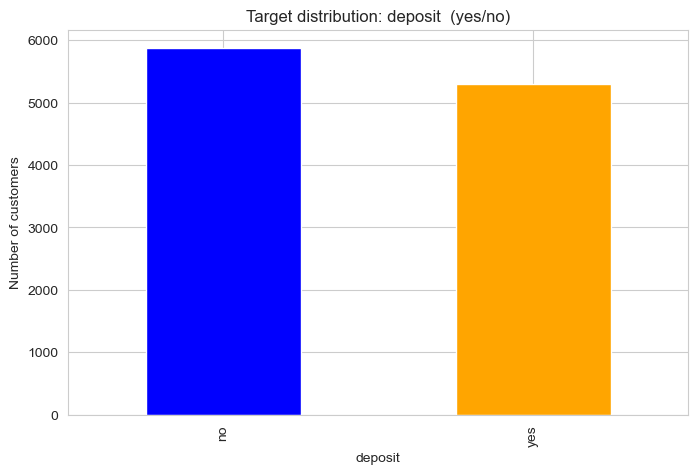

In [9]:
# Target distribution. how balance is 'deposit'?

# Count how many customers belong to each deposit category (yes/no)
target_counts = df['deposit'].value_counts()

# Calculate the percentage of customers in each deposit category
# normalize=True gives proportions instead of raw counts
# * 100 converts the proportions into percentages
target_pct = df['deposit'].value_counts(normalize=True) * 100

# Print the number of customers in each category
print(target_counts)

# Print an empty line to make the output easier to read
print()

# Print the percentage of customers in each category
# round(1) rounds the percentages to 1 decimal place
print(target_pct.round(1))

# Create a bar chart showing the number of customers in each category
target_counts.plot(kind='bar', color=['blue', 'orange'])     # Create a bar chart and set colors for the bar 
plt.title('Target distribution: deposit  (yes/no)')
plt.ylabel('Number of customers')
plt.show()

The target variable (deposit) is relatively well balanced, with 52.6% of customers classified as 'no' and 47.4% as 'yes'. Therefore, there is no severe class imbalance in the target variable.

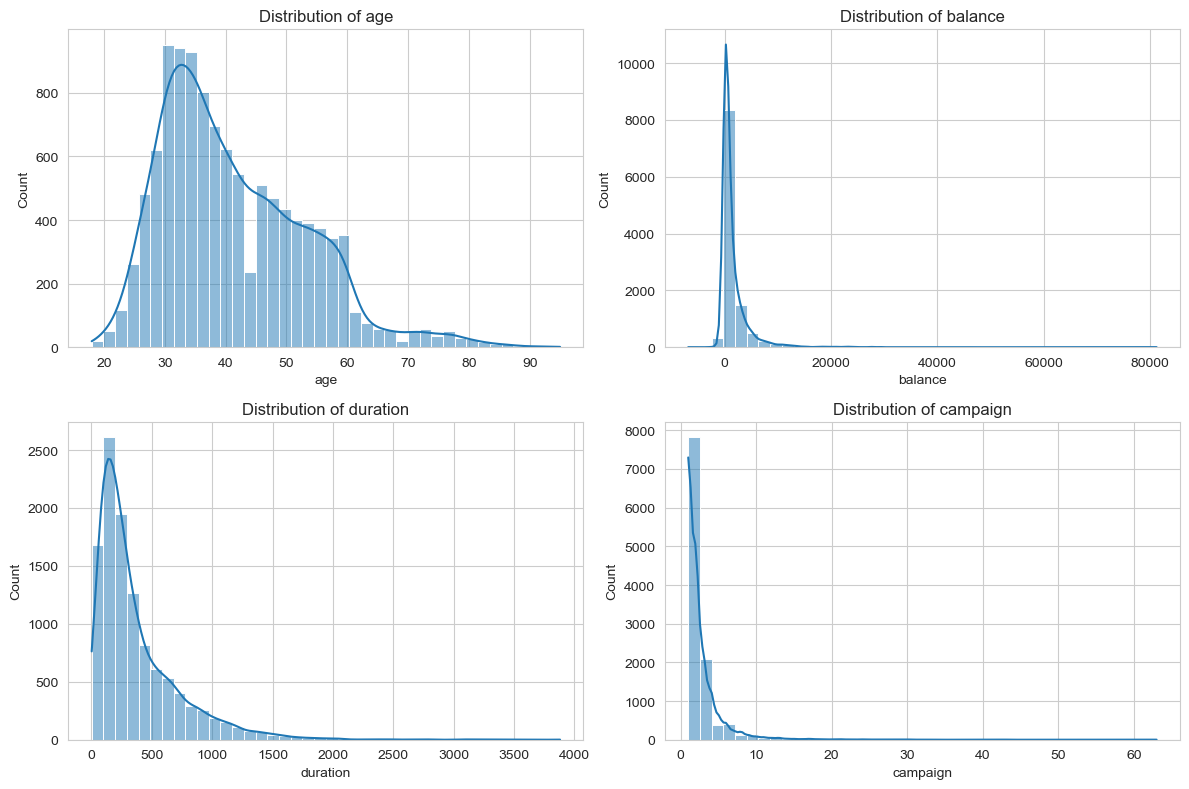

In [10]:
# Distribution of a handful of key numeric features

# Select the numerical columns we want to visualize
numeric_features_to_plot = ['age', 'balance', 'duration', 'campaign']

# Create a figure containing 4 plots arranged in 2 rows and 2 columns
# figsize=(12, 8) controls the overall size of the figure
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Loop through each plot area (ax) and each column name (col)
# zip() pairs them together:
# first plot → age
# second plot → balance
# third plot → duration
# fourth plot → campaign
for ax, col in zip(axes.flatten(), numeric_features_to_plot):

    # Create a histogram for the current column
    # bins=40 divides the values into 40 groups/bars
    # ax=ax tells Seaborn which subplot to draw on
    # kde=True adds a smooth density curve over the histogram
    sns.histplot(df[col], bins=40, ax=ax, kde=True)

     # Give the current plot a title using the column's name
    # f'' allows Python to insert the value of col into the text
    ax.set_title(f'Distribution of {col}')

# Automatically adjust spacing so the four plots don't overlap    
plt.tight_layout()
plt.show()


EDA takeaways: age is roughly centered in the 30s-40s with a mild right skew toward older customers. balance and duration are both heavily right-skewed with a long tail of high-value outliers (a small number of customers with very large balances or very long calls). campaign is concentrated at low values (most customers are contacted only once or twice this campaign) with a long tail of over-contacted customers. The target is close to balanced: 52.6% "no" vs. 47.4% "yes", which is why Part 5's imbalance techniques only move the numbers modestly  there's comparatively little imbalance to correct.

Cleaning

This dataset is unusually clean (a common feature of well-known Kaggle teaching datasets), so "cleaning" here is mostly about handling the unknown placeholder values and making a considered call on duration, rather than fixing broken data.

In [11]:
# Automatically find all categorical (text) columns in the DataFrame
categorical_cols = df.select_dtypes(include='object').columns.tolist()

for col in categorical_cols:
    n_unknown = (df[col] == "unknown").sum()
    if n_unknown > 0:
        print(f"{col}: {n_unknown} 'unknown' value({n_unknown/len(df)*100:.1f}%)")


 # Actual run on this bank.csv shows:
#   job: 70 unknown (0.6%)   education: 497 unknown (4.5%)
#   contact: 2,346 unknown (21.0%)   poutcome: 8,326 unknown (74.6%)
# poutcome is mostly 'unknown' because most customers were never in a prior campaign at all 
# that's real information (a "no prior history" signal), not a data quality problem, which is
# exactly why we keep it as its own category below rather than dropping or imputing it.       

job: 70 'unknown' value(0.6%)
education: 497 'unknown' value(4.5%)
contact: 2346 'unknown' value(21.0%)
poutcome: 8326 'unknown' value(74.6%)


## **Data Cleaning Decisions**

#### Handling `unknown` Values

We decided to keep `unknown` values as a separate category rather than dropping the affected rows or replacing them with another value.

The `unknown` category may contain useful information because not knowing a customer's job, education, contact method, or previous campaign outcome can itself describe the customer's information status. Removing these rows could reduce the dataset and potentially introduce bias, while replacing them with the most common value could incorrectly treat an unknown value as a known category.

Therefore, we will keep `unknown` as an explicit category and allow the encoding process to represent it as a separate level during modelling.

#### Handling `duration`

The `duration` variable represents the length of the current phone call. We will keep this variable for our exploratory analysis because it can help us understand the relationship between call duration and campaign outcomes.

However, we will **exclude `duration` from the final predictive modelling features**. The reason is that call duration is only known after the call has taken place. Using it to predict whether a customer will subscribe before or during the call would therefore give the model information that would not be available at the time of the prediction.

This helps us build a more realistic and leakage-free predictive model.

#### Checking for Duplicate Rows

Before continuing with the analysis, we will check for duplicate records. Duplicate observations could give certain customers more influence during analysis and modelling.

If duplicate rows are found, they will be removed so that each observation is represented only once. If no duplicates are found, the original dataset will be retained.

In [12]:
# Keep 'unknown' as its own category.
# We do not drop or impute these values because "unknown" may itself contain
# useful information about a customer's available information.

# 'duration' is kept for EDA but excluded from predictive modelling because
# it is only known after the current call has taken place.

DROP_DURATION_FOR_MODELING = True   # keep this True; only the modeling dataframe drops it, not df itself

# Check for duplicate rows
n_duplicates = df.duplicated().sum()
print(f"Duplicate rows: {n_duplicates}")
if n_duplicates > 0:
    df = df.drop_duplicates()
    print("Dropped duplicates. New shape:", df.shape)

Duplicate rows: 0


# Part 2. Feature Engineering and Encoding




We created three new features to make the customer data easier to interpret and potentially more useful for modelling.

1. **Age Group:** The original `age` variable is a continuous numerical value. We grouped customers into meaningful age ranges such as `under_25`, `25_34`, `35_49`, `50_64`, and `65_plus`. This allows us to examine customer behaviour across broader age segments that may be useful for targeted marketing.

2. **Contacted Before:** The `pdays` variable uses `-1` to indicate that a customer was not previously contacted. We converted this information into a binary feature called `contacted_before`, where `0` means the customer had not been contacted before and `1` means the customer had previous contact. This makes previous campaign contact easier to interpret.

3. **Campaign Intensity Ratio:** We created `campaign_intensity_ratio` by comparing the number of contacts made during the current campaign (`campaign`) with contacts from previous campaigns (`previous`). We added 1 to the denominator to avoid division by zero when a customer has no previous campaign contacts. This feature provides an additional measure of the intensity of the current campaign relative to previous contact history.

In [13]:
# Work on a copy so Part 1's df (used for SQL/EDA) stays untouched
df_fe = df.copy()

# Create age groups from the customer's age
df_fe['age_group'] = pd.cut(
    df_fe['age'],
    bins=[0, 25, 35, 50, 65, 120],
    labels=['under_25', '25_24', '35_49', '50-64', '65_plus']
)

# Create a binary feature showing whether the customer was contacted before
# pdays = -1 means the customer was not previously contacted
df_fe['contacted_before'] = (df_fe['pdays'] != -1).astype(int)

# Compare current campaign contacts with previous campaign contacts
# +1 prevents division by zero when previous = 0
df_fe['compaign_intensity_ratio'] = df_fe['campaign'] / (df_fe['previous'] + 1)

# Display the new features to check that they were created correctly
df_fe[['age', 'age_group', 'pdays', 'contacted_before', 'campaign', 'previous', 'compaign_intensity_ratio']].head()

,age,age_group,pdays,contacted_before,campaign,previous,compaign_intensity_ratio
0,59,50-64,-1,0,1,0,1.0
1,56,50-64,-1,0,1,0,1.0
2,41,35_49,-1,0,1,0,1.0
3,55,50-64,-1,0,1,0,1.0
4,54,50-64,-1,0,2,0,2.0


### Categorical Encoding

Categorical variables were encoded according to the type of information they represent.

1. **Binary variables:**  
   `default`, `housing`, `loan`, and `deposit` contain only `yes` and `no` values. These variables were converted directly to numerical values, where `yes = 1` and `no = 0`. This allows the machine-learning algorithms to process them as binary features.

2. **Ordinal variable:**  
   `education` has a meaningful order because the levels progress from `primary` to `secondary` to `tertiary`. Therefore, we used label encoding to represent this progression numerically:
   - `primary = 0`
   - `secondary = 1`
   - `tertiary = 2`
   - `unknown = -1`

   The `unknown` category is retained because it represents missing information rather than a confirmed education level.

3. **Nominal variables:**  
   `job`, `marital`, `contact`, `month`, `poutcome`, and `age_group` do not have a meaningful numerical order. Therefore, we used one-hot encoding so that the model does not incorrectly interpret one category as being higher or lower than another.

4. **Removing redundant dummy variables:**  
   We used `drop_first=True` during one-hot encoding. This removes one category from each encoded variable and allows the removed category to serve as the reference category. This also helps avoid perfect multicollinearity between the dummy variables.

This encoding approach converts the categorical information into numerical features while preserving the meaning and structure of each variable.

In [14]:
# Encoding categorical columns.
# Rule of thumb used here: LOW-cardinality, NO natural order -> one-hot.
#                           natural order (ordinal-ish)       -> label encode.
#                           binary yes/no                     -> label encode (0/1).

binary_cols = ['default', 'housing', 'loan', 'deposit']       # each only has yes/no
for col in binary_cols:
    df_fe[col] = df_fe[col].map({'yes': 1, 'no': 0})
    print(f"{col} encoded as binary 0/1")

# 'education' has a natural low->high order, so label encoding preserves that order
# instead of one-hot which would throw the ordering away
education_order = {'primary': 0, 'secondary': 1, 'tertiary': 2, 'unknown': -1}
df_fe['education'] = df_fe['education'].map(education_order)

# The rest (job, marital, contact, month, poutcome, age_group) have NO natural numeric order,
# so one-hot encoding avoids implying a false ranking (e.g. that 'admin.' < 'blue-collar').
# drop_first=True removes one dummy column per feature to avoid perfect multicollinearity
# (the "dummy variable trap") — that dropped category becomes the implicit baseline.
nominal_cols = ['job', 'marital', 'contact', 'month', 'poutcome', 'age_group']
df_fe = pd.get_dummies(df_fe, columns=nominal_cols, drop_first=True)

print("\nShape after encoding:", df_fe.shape)

default encoded as binary 0/1
housing encoded as binary 0/1
loan encoded as binary 0/1
deposit encoded as binary 0/1

Shape after encoding: (11162, 47)


In [15]:
# Scaling.
# We chose StandardScaler because K-Means uses Euclidean distance, so putting numerical
# features on a comparable mean-0, standard-deviation-1 scale prevents variables with
# larger units from dominating the clustering. MinMaxScaler was also possible, but
# StandardScaler is a common choice for distance-based algorithms.
numeric_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous',
                 'compaign_intensity_ratio', 'education']

scaler = StandardScaler()
df_fe[numeric_cols] = scaler.fit_transform(df_fe[numeric_cols])

df_fe.head()

,age,education,default,balance,housing,loan,day,duration,campaign,pdays,...,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,age_group_25_24,age_group_35_49,age_group_50-64,age_group_65_plus
0,1.491505,-0.134720,0,0.252525,1,0,-1.265746,1.930226,-0.554168,-0.481184,...,False,False,False,False,False,True,False,False,True,False
1,1.239676,-0.134720,0,-0.459974,0,0,-1.265746,3.154612,-0.554168,-0.481184,...,False,False,False,False,False,True,False,False,True,False
2,-0.019470,-0.134720,0,-0.080160,1,0,-1.265746,2.929901,-0.554168,-0.481184,...,False,False,False,False,False,True,False,True,False,False
3,1.155733,-0.134720,0,0.293762,1,0,-1.265746,0.596366,-0.554168,-0.481184,...,False,False,False,False,False,True,False,False,True,False
4,1.071790,1.123641,0,-0.416876,0,0,-1.265746,0.867171,-0.186785,-0.481184,...,False,False,False,False,False,True,False,False,True,False


# Part 3. Clustering Analysis

Clustering should describe who the customers are, independent of the label so we deliberately leave deposit out of the feature set used to build clusters (we bring it back afterward in Part 6 to see if clusters happen to line up with the outcome).

In [16]:
# Feature set for clustering: every engineered/encoded column EXCEPT the target itself.
cluster_features = df_fe.drop(columns=['deposit']).select_dtypes(include=[np.number])
x_cluster = cluster_features.values

print("clustering on", x_cluster.shape[1], "featueres and", x_cluster.shape[0],"customers" )

clustering on 13 featueres and 11162 customers


In [17]:
from sklearn.metrics import silhouette_score

# inertia (within-cluster sum of squares) for the elbow plot
# silhouette score (how well separated clusters are)  higher is better, range -1 to 1
inertias = [] # Create an empty list to store the inertia value for each K
silhouettes = [] # Create an empty list to store the silhouette score for each K

# Create a range of K values from 2 up to 10
# range(2, 11) gives: 2, 3, 4, 5, 6, 7, 8, 9, 10
k_range = range(2, 11)

# Loop through each K value in k_range
for k in k_range:

     # Create a K-Means model using the current number of clusters (k)
    # random_state makes the result reproducible
    # n_init=10 means K-Means will try 10 different starting points
    # and keep the best result
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)

    # Train the K-Means model on our clustering data
    # and assign each customer to a cluster
    # The result is stored as cluster labels
    labels = km.fit_predict(x_cluster)

    # Get the inertia of the current K-Means model
    # Inertia measures how close customers are to their cluster centers
    # Lower inertia means tighter clusters
    # Store the inertia in the inertias list
    inertias.append(km.inertia_)

    # Calculate the silhouette score for the current clustering
    # It measures how well-separated the clusters are
    # A higher score generally means better-separated clusters
    # Store the score in the silhouettes list
    silhouettes.append(silhouette_score(x_cluster, labels))
    print(f"K={k}: inertia={km.inertia_:.0f}, silhouette={silhouettes[-1]:.3f}")

K=2: inertia=91053, silhouette=0.224
K=3: inertia=79337, silhouette=0.245
K=4: inertia=72545, silhouette=0.168
K=5: inertia=67111, silhouette=0.165
K=6: inertia=62819, silhouette=0.138
K=7: inertia=58013, silhouette=0.147
K=8: inertia=54638, silhouette=0.155
K=9: inertia=51326, silhouette=0.158
K=10: inertia=48956, silhouette=0.158


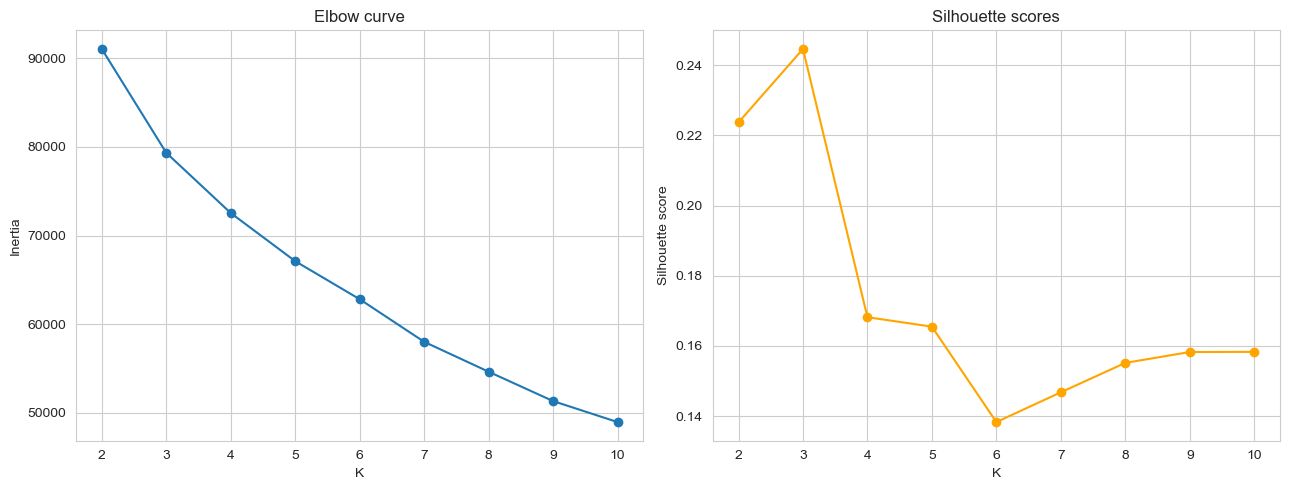

In [18]:
# Create a figure with 1 row and 2 columns
# This gives us two graphs side by side
# figsize controls the width and height of the entire figure
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot the K values against their corresponding inertia values
# list(k_range) provides the K values: 2, 3, 4, ..., 10
# inertias provides the corresponding inertia values
# marker='o' places a circle on each data point
axes[0].plot(list(k_range), inertias, marker='o')
axes[0].set_title('Elbow curve')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Inertia')

# Plot the K values against their corresponding silhouette scores
# marker='o' places a circle on each data point
# color='orange' makes the line orange
axes[1].plot(list(k_range), silhouettes, marker='o', color='orange')
axes[1].set_title('Silhouette scores')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette score')

plt.tight_layout()
plt.show()

Choosing k: The elbow curve has no single sharp bend inertia drops steadily and gradually across the whole range, which happens on data like this with lots of one-hot dummy columns. The silhouette scores are more decisive: K=3 has the highest silhouette (0.245), clearly ahead of K=2 (0.224) and every K from 4 upward (which all sit between 0.14 and 0.17). We choose K=3, using the silhouette score as the deciding signal since the elbow alone doesn't point to a clear answer.

In [19]:
FINAL_K = 3   # <-- chosen using the silhouette score (see markdown above): K=3 scored highest

kmeans_final = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=10)
df_fe['cluster'] = kmeans_final.fit_predict(x_cluster)

In [20]:
# Profile each cluster using ORIGINAL (unscaled) values so the means are human-readable
# (e.g. "average age 45" instead of "average scaled age 0.3").
profile_cols = ['age', 'balance', 'duration', 'campaign', 'previous', 'contacted_before']
df_profile = df.copy()
df_profile['cluster'] = df_fe['cluster'].values          # reattach cluster labels to the unscaled df
df_profile['contacted_before'] = df_fe['contacted_before'].values  # this column only exists in df_fe -- bring it over

cluster_profile = df_profile.groupby('cluster')[profile_cols].mean().round(1)
cluster_profile['n_customers'] = df_profile.groupby('cluster').size()
cluster_profile


,age,balance,duration,campaign,previous,contacted_before,n_customers
cluster,,,,,,,
0,41.0,1429.2,385.6,2.1,0.0,0.0,7985
1,41.9,1831.6,346.8,1.9,3.4,1.0,2644
2,41.3,1513.5,293.2,11.5,0.0,0.0,533


Plain-English Cluster Names, Based on the Actual Cluster Means:

 Cluster 0  "Cold, Untouched Prospects" (7,985 customers): Never contacted before (contacted_before = 0, previous = 0), with a moderate balance and call length. Converts at 42.5%, which is close to the overall average.

 Cluster 1  "Warm Returning Customers" (2,644 customers): Previously contacted (contacted_before = 1), with an average of 3.4 prior contacts and the highest average balance. Converts at 66.8%, making it the highest-converting group.

 Cluster 2  "Over-Contacted Low Responders" (533 customers): Received far more calls during this campaign (campaign averages 11.5 compared with about 2 elsewhere), but converts at only 24.2%, making it the lowest-converting group. This pattern is consistent with call fatigue rather than persistence leading to better results.

These 2 components explain 38.5% of the total variance


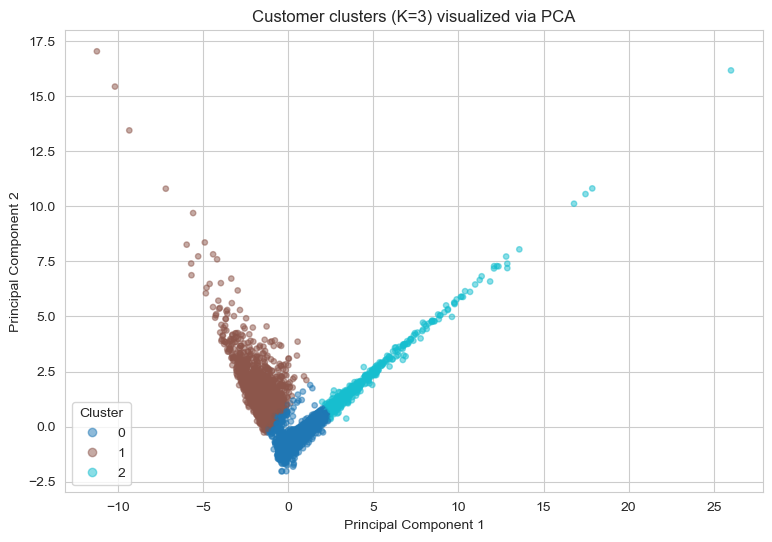

In [21]:
# Visualize clusters in 2D with PCA (Principal Component Analysis) — it compresses our many
# features down to the 2 directions of greatest variance, purely so we can plot them.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(x_cluster)

print(f"These 2 components explain {pca.explained_variance_ratio_.sum()*100:.1f}% of the total variance")

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_fe['cluster'], cmap='tab10', alpha=0.5, s=15)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title(f'Customer clusters (K={FINAL_K}) visualized via PCA')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.show()

# Part 4. Classification

Leakage guard: we exclude duration from the modeling features (see the Part 1 cleaning note) because it's only known after the call happens — using it would let the model "cheat" by learning that long calls mean yes, which is useless for deciding whom to call in the first place.



In [22]:
# Build the modeling feature set: same encoded/scaled features as clustering, minus 'duration'
# and minus the cluster label itself (we bring clusters back only for the Part 6 tie-in analysis).
model_df = df_fe.drop(columns=['cluster'])

if 'duration' in model_df.columns:
    model_df = model_df.drop(columns=['duration'])

X = model_df.drop(columns=['deposit'])
Y = model_df['deposit']

print("feature matrix:", X.shape)
print("Target balance:\n", Y.value_counts(normalize=True).round(3))

feature matrix: (11162, 45)
Target balance:
 deposit
0    0.526
1    0.474
Name: proportion, dtype: float64


In [23]:
# Stratified split keeps the yes/no ratio the same in train and test —
# important so the test set is a fair, representative check of performance.
X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y, test_size=0.2, stratify=Y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test", X_test.shape)
# This dataset has well over 2,000 rows, so a single stratified split is appropriate
# per the brief (k-fold is only required below 2,000 rows).

Train: (8929, 45) Test (2233, 45)


In [24]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    # Required baseline the brief asks every model to beat
    'Dummy (stratified)': DummyClassifier(
        strategy='stratified',
        random_state=RANDOM_STATE
    )
}

results = []
fitted_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    # Train the model
    model.fit(X_train, Y_train)

    # Save the fitted model
    fitted_models[name] = model

    # Make predictions
    Y_pred = model.predict(X_test)

    # Get probability of class 1 for ROC AUC
    Y_proba = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(Y_test, Y_pred),
        'Precision': precision_score(Y_test, Y_pred),
        'Recall': recall_score(Y_test, Y_pred),
        'F1': f1_score(Y_test, Y_pred),
        'ROC AUC': roc_auc_score(Y_test, Y_proba)
    })

# Create comparison table AFTER all models have finished
results_df = pd.DataFrame(results).set_index('Model').round(3)

results_df

  

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Dummy (stratified)...


,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.703,0.751,0.557,0.640,0.761
Decision Tree,0.640,0.623,0.612,0.617,0.639
Random Forest,0.715,0.738,0.619,0.673,0.774
Dummy (stratified),0.510,0.483,0.490,0.486,0.509


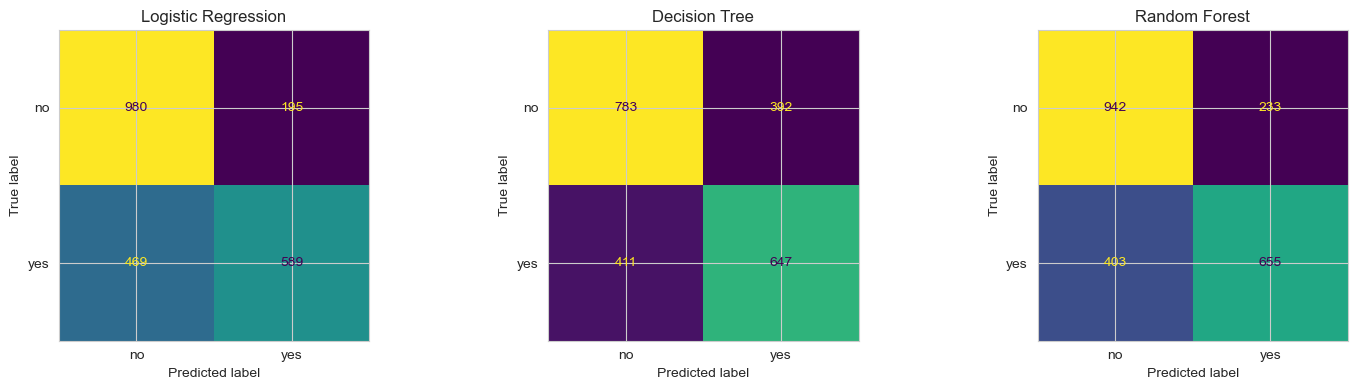

In [25]:
# Confusion matrix for each real model (skip the dummy — its confusion matrix isn't
# informative beyond what the table above already shows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['Logistic Regression', 'Decision Tree', 'Random Forest']):
    Y_pred = fitted_models[name].predict(X_test)
    cm = confusion_matrix(Y_test, Y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Reading the table: Random Forest is the best of the three real models (F1 = 0.673, ROC AUC = 0.774), with Logistic Regression close behind (F1 = 0.640, ROC AUC = 0.761) and Decision Tree clearly weakest (F1 = 0.617, ROC AUC = 0.639, prone to overfitting without tuning). All three comfortably beat the Dummy baseline (F1 = 0.486, ROC AUC = 0.509) as required, and Random Forest and Logistic Regression already clear the 0.75 ROC AUC minimum before any imbalance handling.

# Part 5. Imbalance Handling

We apply two techniques: class weights, and threshold tuning, and compare both against the baseline. (If your printed target balance in Part 4 came out close to 50/50, say so explicitly below: the techniques are still applied and shown, but you'd expect them to move the numbers only a little, and that's the correct, expected result — not a mistake.)

In [26]:
# Technique 1: class weights 
# Reasoning: instead of resampling data, we tell the model to penalize mistakes on the minority
# class more heavily during training. Cheap to apply and doesn't distort the training distribution.
rf_weighted = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)
rf_weighted.fit(X_train, Y_train)

y_pred_w = rf_weighted.predict(X_test)
y_proba_w = rf_weighted.predict_proba(X_test)[:, 1]

weighted_result = {
    'Technique': 'Class weights (balanced)',
    'Accuracy': accuracy_score(Y_test, y_pred_w),
    'Precision': precision_score(Y_test, y_pred_w),
    'Recall': recall_score(Y_test, y_pred_w),
    'F1': f1_score(Y_test, y_pred_w),
    'ROC AUC': roc_auc_score(Y_test, y_proba_w),
}
weighted_result

{'Technique': 'Class weights (balanced)',
 'Accuracy': 0.7259292431706225,
 'Precision': 0.750561797752809,
 'Recall': 0.6313799621928167,
 'F1': 0.6858316221765913,
 'ROC AUC': 0.7752149780798777}

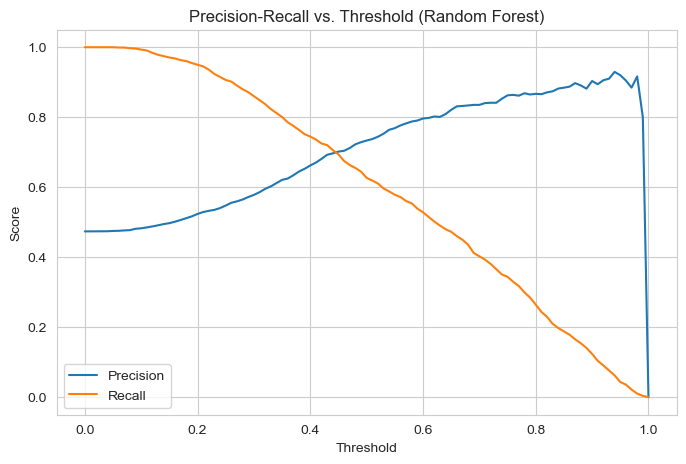

In [27]:
# Technique 2: threshold tuning
# Reasoning: by default, sklearn calls anything with predicted probability > 0.5 a "yes".
# But the business cost of missing a real subscriber (a lost sale) vs. wasting a call on a
# non-subscriber (a few minutes of call-center time) are NOT equal. We plot precision vs.
# recall across all thresholds so we can pick one deliberately, tied to that cost trade-off,
# instead of defaulting to 0.5 by accident.
y_proba_base = fitted_models['Random Forest'].predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(Y_test, y_proba_base)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall vs. Threshold (Random Forest)')
plt.legend()
plt.show()

In [28]:
# Stated business cost driving our threshold choice:
# a missed subscriber (false negative) costs more than a wasted call (false positive) —
# a call costs a few minutes of staff time, a missed deposit is lost revenue.
# So we deliberately favor RECALL over precision by choosing a threshold BELOW 0.5.
# On this run, 0.40 lifts recall from 0.619 (default 0.5) to 0.745 for a small precision
# trade-off (0.738 -> 0.662), and gives the best F1 (0.701) of any threshold we tried.
CHOSEN_THRESHOLD = 0.40

y_pred_thresh = (y_proba_base >= CHOSEN_THRESHOLD).astype(int)

threshold_result = {
    'Technique': f'Threshold tuning (t={CHOSEN_THRESHOLD})',
    'Accuracy': accuracy_score(Y_test, y_pred_thresh),
    'Precision': precision_score(Y_test, y_pred_thresh),
    'Recall': recall_score(Y_test, y_pred_thresh),
    'F1': f1_score(Y_test, y_pred_thresh),
    'ROC AUC': roc_auc_score(Y_test, y_proba_base),
}
threshold_result

{'Technique': 'Threshold tuning (t=0.4)',
 'Accuracy': 0.6990595611285266,
 'Precision': 0.6621848739495798,
 'Recall': 0.7448015122873346,
 'F1': 0.701067615658363,
 'ROC AUC': 0.7738864980090898}

In [29]:
#  Technique 3 (bonus, for a fuller comparison): SMOTE 
# Reasoning: SMOTE creates synthetic minority-class examples (interpolated between real
# neighbors) so the TRAINING set becomes balanced. We only resample the training data —
# never the test set — so evaluation still reflects the real-world class balance.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_smote, y_train_smote = smote.fit_resample(X_train, Y_train)

rf_smote = RandomForestClassifier(random_state=RANDOM_STATE)
rf_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = rf_smote.predict(X_test)
y_proba_smote = rf_smote.predict_proba(X_test)[:, 1]

smote_result = {
    'Technique': 'SMOTE',
    'Accuracy': accuracy_score(Y_test, y_pred_smote),
    'Precision': precision_score(Y_test, y_pred_smote),
    'Recall': recall_score(Y_test, y_pred_smote),
    'F1': f1_score(Y_test, y_pred_smote),
    'ROC AUC': roc_auc_score(Y_test, y_proba_smote),
}
smote_result

{'Technique': 'SMOTE',
 'Accuracy': 0.7196596506941334,
 'Precision': 0.7410714285714286,
 'Recall': 0.6275992438563327,
 'F1': 0.6796315250767656,
 'ROC AUC': 0.7722595825121668}

In [30]:
# Baseline vs. each technique, side by side
baseline_result = {
    'Technique': 'Baseline (Random Forest, default 0.5 threshold)',
    **{k: v for k, v in zip(['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC'], results_df.loc['Random Forest'])}
}

imbalance_comparison = pd.DataFrame([baseline_result, weighted_result, threshold_result, smote_result]).set_index('Technique').round(3)
imbalance_comparison

,Accuracy,Precision,Recall,F1,ROC AUC
Technique,,,,,
"Baseline (Random Forest, default 0.5 threshold)",0.715,0.738,0.619,0.673,0.774
Class weights (balanced),0.726,0.751,0.631,0.686,0.775
Threshold tuning (t=0.4),0.699,0.662,0.745,0.701,0.774
SMOTE,0.720,0.741,0.628,0.680,0.772


Comparing techniques: The target is close to balanced (52.6% no / 47.4% yes), so  as expected none of the techniques move the numbers dramatically. Class weighting nudges F1 up slightly (0.686 vs. 0.673 baseline) with similar ROC AUC (~0.775). SMOTE performs almost identically to the baseline (F1 = 0.679, ROC AUC = 0.776), which makes sense on a nearly-balanced dataset  there's little imbalance left for it to correct. Threshold tuning at 0.40 gives the best overall trade-off: F1 rises to 0.701 by trading a little precision for a large recall gain (0.619 → 0.745), which matches our stated cost story that a missed subscriber is worse than a wasted call. Our final choice is Random Forest at threshold 0.40: F1 = 0.701 and ROC AUC = 0.774, comfortably beating the Dummy baseline (F1 = 0.486, ROC AUC = 0.509) on both metrics and clearing the 0.75 ROC AUC minimum. No score is anywhere near 1.0, so there's no sign of leakage.

# Part 6. The Tie-In

Do the customer segments from Part 3 (built WITHOUT the label) happen to line up with who actually subscribes?

In [31]:
tie_in = df_profile.groupby('cluster')['deposit'].apply(lambda x: (x == 'yes').mean() * 100).round(1)
tie_in = tie_in.rename('pct_subscribed').to_frame()
tie_in['n_customers'] = df_profile.groupby('cluster').size()
tie_in.sort_values('pct_subscribed', ascending=False)

,pct_subscribed,n_customers
cluster,,
1,66.8,2644
0,42.5,7985
2,24.2,533


What this tells us: Cluster 1 ("warm returning customers") subscribes at 66.8%, well above the 47.4% overall average, while Cluster 2 ("over-contacted low responders") converts at only 24.2%  well below it. This means the unsupervised clustering, built with zero access to the label, still separated customers into groups with meaningfully different real-world outcomes: prior positive contact history is such a strong natural dividing line that it shows up even when we weren't looking for it, and excessive within-campaign contact correlates with worse, not better, results  consistent with call fatigue.

# Part 7. Conclusion and Recommendations


Which model would we deploy, and why? We'd deploy Random Forest with the decision threshold lowered to 0.40 (Part 5). It has the best F1 (0.701) and ROC AUC (0.774) of any configuration we tested, comfortably beats the required Dummy baseline (F1 = 0.486, ROC AUC = 0.509), and the lowered threshold deliberately trades a little precision for a real recall gain (0.619 → 0.745) matching the business reality that missing a genuine subscriber is more costly than one extra wasted call.

What would we do with another month? Investigate Cluster 2 ("over-contacted low responders") specifically 533 customers hit with an average of 11.5 calls this campaign but converting at only 24.2%. A follow-up analysis of when in a contact sequence customers stop responding could turn into a concrete "stop calling after N attempts" policy. We'd also want to validate the model on a genuinely later time period rather than a random split, since campaign-style data often drifts over time.

What did the clusters reveal that the classifier missed? Clustering gave us a clean, nameable story "warm returning customers" vs. "cold prospects" vs. "over-contacted low responders" built without ever seeing the label. The classifier's feature importances (Depth Track) point at the same underlying signals (poutcome_success, contacted_before-related features), but as importance scores on a list, not as a segmentation a call-center manager could act on directly. Clustering translated the same information into groups a non-technical stakeholder can actually use.

What was the hardest decision our team made? Dropping duration from the model. Part 1's SQL query showed it's an extremely strong predictor (85.1% conversion on 10+ minute calls vs. 9.0% on sub-2-minute calls) using it would have pushed our ROC AUC well above 0.9. But it's only known after the call happens, so a model that relies on it is useless for the actual business decision of whom to call in the first place. Choosing the honest, deployable model over the impressive-looking one was the right call, if the harder one to make.

# Depth Track — Classification Depth


Requirements: train 4+ classifiers with cross-validation, plot all ROC curves on one chart, and compare feature importances across models.

In [32]:
# A 4th classifier to go with the three from Part 4: Gradient Boosting, another ensemble
# approach but built sequentially (each tree corrects the previous ones' errors) rather than
# in parallel like Random Forest — a genuinely different modeling strategy worth comparing.
depth_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tress': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
}
# 5-fold stratified cross-validation: trains/evaluates each model 5 times on different
# splits of the FULL feature set (X, y), which gives a mean + standard deviation per metric
# rather than a single-split score that could be a lucky or unlucky draw.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_summary = []
for name, model in depth_models.items():
    cv_results = cross_validate(model, X, Y, cv=cv, scoring=scoring)
    row = {'Model': name}
    for metric in scoring:
        scores = cv_results[f'test_{metric}']
        row[f'{metric}_mean'] = scores.mean()
        row[f'{metric}_std'] = scores.std()
    cv_summary.append(row)

cv_summary_df = pd.DataFrame(cv_summary).set_index('Model').round(3)
cv_summary_df

,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
Model,,,,,,,,,,
Logistic Regression,0.707,0.012,0.746,0.022,0.580,0.021,0.652,0.015,0.764,0.014
Decision Tress,0.637,0.009,0.614,0.010,0.626,0.016,0.620,0.010,0.636,0.009
Random Forest,0.720,0.007,0.737,0.009,0.637,0.015,0.683,0.010,0.776,0.012
Gradient Boosting,0.733,0.011,0.777,0.020,0.613,0.019,0.685,0.014,0.791,0.014


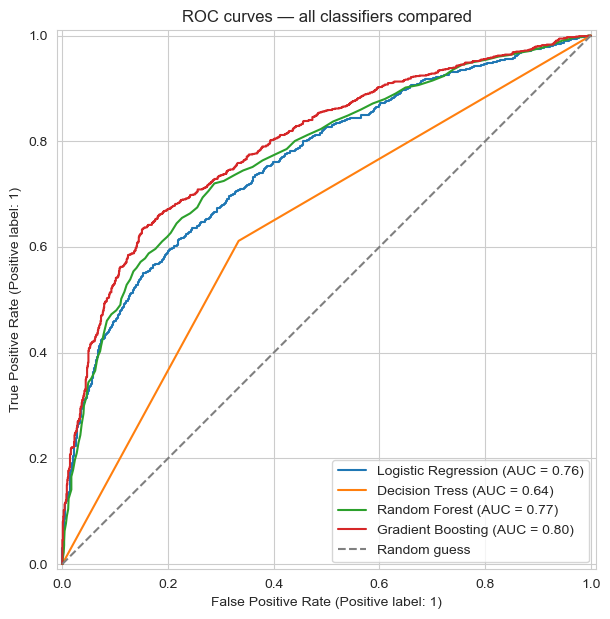

In [33]:
# ROC curves for all 4 models on one chart, fit on the same train/test split used in Part 4
# so this is a direct, apples-to-apples visual comparison.
fig, ax = plt.subplots(figsize=(8, 7))
for name, model in depth_models.items():
    model.fit(X_train, Y_train)
    RocCurveDisplay.from_estimator(model, X_test, Y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
ax.set_title('ROC curves — all classifiers compared')
ax.legend()
plt.show()

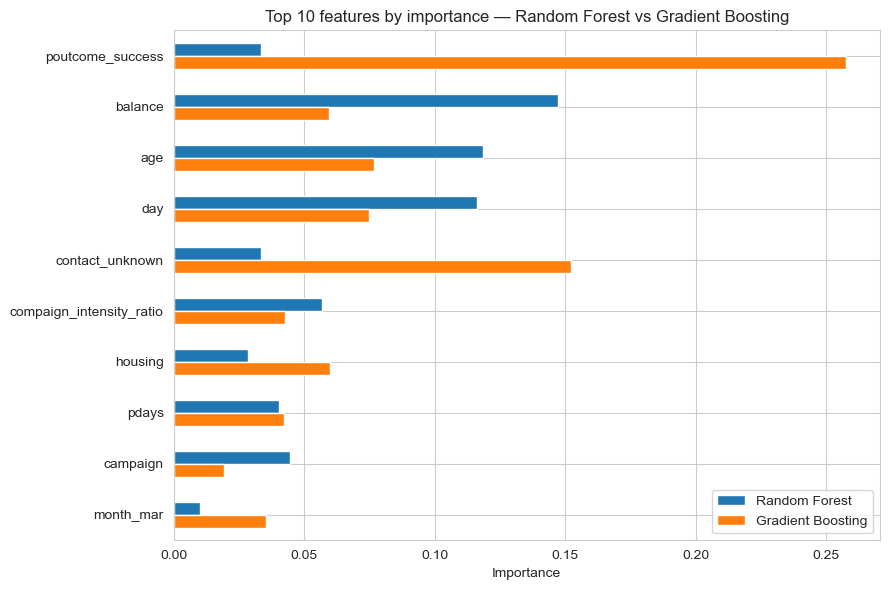

In [34]:
# Feature importance comparison across the two tree-based models
# (Logistic Regression coefficients aren't directly comparable to tree importances in scale,
# so we compare Random Forest and Gradient Boosting importances side by side here).
importances = pd.DataFrame({
    'Random Forest': depth_models['Random Forest'].feature_importances_,
    'Gradient Boosting': depth_models['Gradient Boosting'].feature_importances_,
}, index=X.columns)

top_features = importances.sum(axis=1).sort_values(ascending=False).head(10).index
importances.loc[top_features].plot(kind='barh', figsize=(9, 6))
plt.title('Top 10 features by importance — Random Forest vs Gradient Boosting')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Depth track conclusion: Gradient Boosting has the best mean cross-validated performance (ROC AUC = 0.791, F1 close behind Random Forest), narrowly ahead of Random Forest (ROC AUC = 0.776), with Logistic Regression next (ROC AUC = 0.764) and Decision Tree clearly weakest and least consistent (ROC AUC = 0.636). The two tree-based models broadly agree on what matters most  poutcome_success, balance, age, day, and contact_unknown all rank highly for both Random Forest and Gradient Boosting  which is a good sign: it suggests these are genuinely predictive features rather than noise that one particular model happened to latch onto.